#  hdf5 file containing space groups and XRD patterns
Yes — you can absolutely use the 230 generated CIF files to create an HDF5 dataset containing space group labels and their corresponding XRD patterns. This is a great step toward building a dataset suitable for machine learning models, especially those that take diffraction patterns as input (like classification or inverse design models).

1. Parse CIF Files - Use pymatgen, ase, or pyxtal to read the CIF files and extract structural data.

2. Simulate XRD Patterns: Use tools like:
    - pymatgen.analysis.diffraction.xrd.XRDCalculator
    - ase.diffraction.xrd.XRDCalculator to simulate the XRD pattern (2θ vs. intensity) from each structure.

3. Prepare the Data for HDF5: Each entry should contain:
    - The space group number
    - The CIF filename or structure
    - The XRD pattern, typically as arrays of angles and intensities

4. Write to HDF5 -Use h5py to store:
{
  "SG_225": {
    "space_group": 225,
    "theta": [...],         # 2θ values
    "intensity": [...],     # corresponding intensities
  },
  ...
}

Optional Preprocessing
- Normalize intensity
- Pad sequences (for uniform length)
- Downsample angles (to reduce resolution)



In [3]:
!pip install h5py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 7.3 MB/s eta 0:00:00a 0:00:01


## Generate hdf5 file 
- Requirements to run code: pip install pymatgen h5py numpy tqdm

generate_xrd_hdf5.py

In [4]:
import os
import h5py
import numpy as np
from pymatgen.core import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from tqdm import tqdm

# Set up directories
cif_dir = "generated_crystal_structures"  # folder where your CIFs are saved
output_file = "xrd_dataset.hdf5"          # output HDF5 filename

# Initialize XRD calculator
xrd_calc = XRDCalculator(wavelength="CuKa")  # Cu-Kα radiation (default)

# Create or overwrite HDF5 file
with h5py.File(output_file, "w") as h5f:
    # Loop over all CIF files
    for cif_name in tqdm(sorted(os.listdir(cif_dir)), desc="Generating XRD patterns"):
        if not cif_name.endswith(".cif"):
            continue

        sg_number = int(cif_name.split("_")[1].split(".")[0])  # Extract SG from filename (e.g., SG_229.cif)

        try:
            # Load structure and compute XRD pattern
            cif_path = os.path.join(cif_dir, cif_name)
            structure = Structure.from_file(cif_path)
            xrd_pattern = xrd_calc.get_pattern(structure)

            # Convert to numpy arrays
            two_theta = np.array(xrd_pattern.x)  # 2-theta angles
            intensities = np.array(xrd_pattern.y)  # intensities

            # Store in HDF5 as a group: SG_###
            grp = h5f.create_group(f"SG_{sg_number}")
            grp.create_dataset("2theta", data=two_theta)
            grp.create_dataset("intensity", data=intensities)
            grp.attrs["space_group"] = sg_number

        except Exception as e:
            print(f"Failed to process {cif_name}: {e}")

print(f"\n✅ HDF5 dataset saved to {output_file}")


Generating XRD patterns:   0%|          | 0/230 [00:00<?, ?it/s]/home/UserD/anaconda3/envs/pyxtal_env/lib/python3.11/site-packages/pymatgen/core/periodic_table.py:278: UserWarning: No Pauling electronegativity for Ar. Setting to NaN. This has no physical meaning, and is mainly done to avoid errors caused by the code expecting a float.
  if not hasattr(other, "X") or not hasattr(other, "symbol"):
/home/UserD/anaconda3/envs/pyxtal_env/lib/python3.11/site-packages/pymatgen/core/periodic_table.py:281: UserWarning: No Pauling electronegativity for Ar. Setting to NaN. This has no physical meaning, and is mainly done to avoid errors caused by the code expecting a float.
  x2 = float("inf") if other.X != other.X else other.X
/home/UserD/anaconda3/envs/pyxtal_env/lib/python3.11/site-packages/pymatgen/core/composition.py:326: UserWarning: No Pauling electronegativity for Ar. Setting to NaN. This has no physical meaning, and is mainly done to avoid errors caused by the code expecting a float.
  r


✅ HDF5 dataset saved to xrd_dataset.hdf5


Script can be ran locally or on TACC.
Next, build the TACC Slurm job script next so you can generate this dataset on their compute nodes efficiently.

## Exploring and Inspecting generated hdf5 file
### Explore structure of entire dataset

In [5]:
import h5py

hdf5_path = "xrd_dataset.hdf5"

with h5py.File(hdf5_path, "r") as f:
    print(" HDF5 File Structure:")
    for sg in f:
        print(f" - {sg}")
        group = f[sg]
        print(f"   ├─ 2theta shape: {group['2theta'].shape}")
        print(f"   ├─ intensity shape: {group['intensity'].shape}")
        print(f"   └─ space group: {group.attrs['space_group']}")


 HDF5 File Structure:
 - SG_1
   ├─ 2theta shape: (546,)
   ├─ intensity shape: (546,)
   └─ space group: 1
 - SG_10
   ├─ 2theta shape: (222,)
   ├─ intensity shape: (222,)
   └─ space group: 10
 - SG_100
   ├─ 2theta shape: (33,)
   ├─ intensity shape: (33,)
   └─ space group: 100
 - SG_101
   ├─ 2theta shape: (133,)
   ├─ intensity shape: (133,)
   └─ space group: 101
 - SG_102
   ├─ 2theta shape: (124,)
   ├─ intensity shape: (124,)
   └─ space group: 102
 - SG_103
   ├─ 2theta shape: (108,)
   ├─ intensity shape: (108,)
   └─ space group: 103
 - SG_104
   ├─ 2theta shape: (101,)
   ├─ intensity shape: (101,)
   └─ space group: 104
 - SG_105
   ├─ 2theta shape: (53,)
   ├─ intensity shape: (53,)
   └─ space group: 105
 - SG_106
   ├─ 2theta shape: (171,)
   ├─ intensity shape: (171,)
   └─ space group: 106
 - SG_107
   ├─ 2theta shape: (22,)
   ├─ intensity shape: (22,)
   └─ space group: 107
 - SG_108
   ├─ 2theta shape: (67,)
   ├─ intensity shape: (67,)
   └─ space group: 108
 -

### Option 2: Inspect a Single Space Group’s Data

In [13]:
with h5py.File(hdf5_path, "r") as f:
    group = f["SG_220"]  # replace with any SG you'd like to inspect
    two_theta = group["2theta"][:]
    intensity = group["intensity"][:]

    print("2θ (degrees):", two_theta[:5])
    print("Intensity:", intensity[:5])


2θ (degrees): [21.90987828 25.35178696 28.40345511 33.7501822  36.15811734]
Intensity: [100.          94.07499824   1.44900087  66.42309428   0.89720767]


In [ ]:
import h5py

file_path = "xrd_dataset.hdf5"

try:
    with h5py.File(file_path, "r") as f:
        print("File loaded successfully!")
        print("Top-level keys/groups:", list(f.keys()))
        for key in f.keys():
            print(f"\nContents of {key}:")
            for item in f[key].keys():
                print(f"  - {item}")
except Exception as e:
    print(" Failed to load the file:", e)


✅ File loaded successfully!
Top-level keys/groups: ['SG_1', 'SG_10', 'SG_100', 'SG_101', 'SG_102', 'SG_103', 'SG_104', 'SG_105', 'SG_106', 'SG_107', 'SG_108', 'SG_109', 'SG_11', 'SG_110', 'SG_111', 'SG_112', 'SG_113', 'SG_114', 'SG_115', 'SG_116', 'SG_117', 'SG_118', 'SG_119', 'SG_12', 'SG_120', 'SG_121', 'SG_122', 'SG_123', 'SG_124', 'SG_125', 'SG_126', 'SG_127', 'SG_128', 'SG_129', 'SG_13', 'SG_130', 'SG_131', 'SG_132', 'SG_133', 'SG_134', 'SG_135', 'SG_136', 'SG_137', 'SG_138', 'SG_139', 'SG_14', 'SG_140', 'SG_141', 'SG_142', 'SG_143', 'SG_144', 'SG_145', 'SG_146', 'SG_147', 'SG_148', 'SG_149', 'SG_15', 'SG_150', 'SG_151', 'SG_152', 'SG_153', 'SG_154', 'SG_155', 'SG_156', 'SG_157', 'SG_158', 'SG_159', 'SG_16', 'SG_160', 'SG_161', 'SG_162', 'SG_163', 'SG_164', 'SG_165', 'SG_166', 'SG_167', 'SG_168', 'SG_169', 'SG_17', 'SG_170', 'SG_171', 'SG_172', 'SG_173', 'SG_174', 'SG_175', 'SG_176', 'SG_177', 'SG_178', 'SG_179', 'SG_18', 'SG_180', 'SG_181', 'SG_182', 'SG_183', 'SG_184', 'SG_185',

Each group in the HDF5 file is named SG_<number> (e.g., SG_1, SG_230), and contains:
- 2theta: The diffraction angles (degrees)
- intensity: The XRD pattern intensities (arbitrary units)

That means we're fully ready for modeling — this dataset can now be:
- Used to train machine learning models (e.g. transformers, CNNs)
- Analyzed by space group
- Augmented or visualized easily

Plot & Inspect Sample Data To visually verify the patterns:

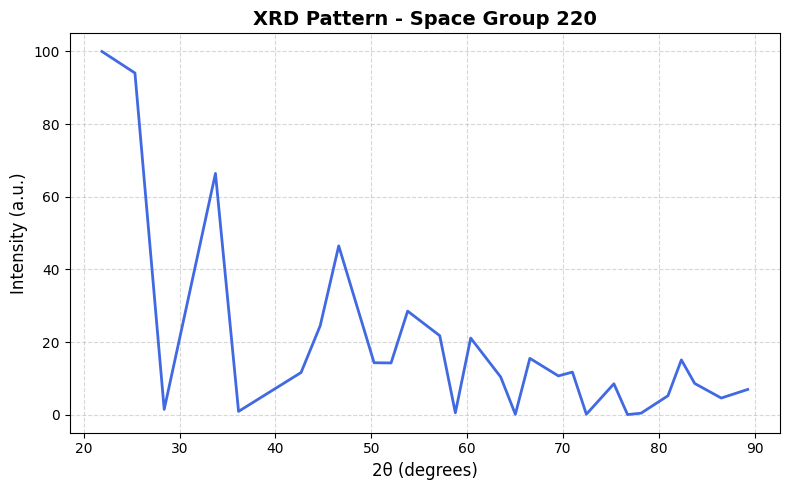

In [11]:
import h5py
import matplotlib.pyplot as plt

# Load XRD pattern from HDF5
with h5py.File("xrd_dataset.hdf5", "r") as f:
    group = f["SG_220"]  # Change to your desired SG
    x = group["2theta"][:]
    y = group["intensity"][:]

# Plot with enhancements
plt.figure(figsize=(8, 5))
plt.plot(x, y, color="royalblue", linewidth=2)

# Styling
plt.xlabel("2θ (degrees)", fontsize=12)
plt.ylabel("Intensity (a.u.)", fontsize=12)
plt.title("XRD Pattern - Space Group 220", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# Optional: Save as image
# plt.savefig("xrd_sg220.png", dpi=300)

plt.show()


This plot is a simulated XRD pattern for space group.It shows a basic single-pattern output for one crystal structure. The XRD pattern itself is just a 1D projection (intensity vs 2θ angle) of the full 3D structure. Meaning it compresses the 3D atomic arrangement into a plot that shows where diffraction peaks occur (based on the Bragg condition and crystal symmetry). That’s what real XRD instruments measure — not the 3D structure directly, but how it diffracts X-rays.

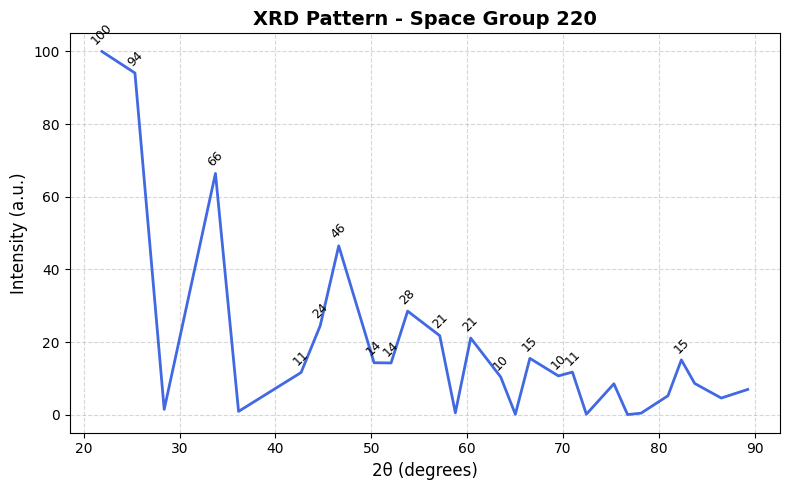

In [ ]:
import h5py
import matplotlib.pyplot as plt

# Load XRD pattern from HDF5
with h5py.File("xrd_dataset.hdf5", "r") as f:
    group = f["SG_220"]  # Change to your desired SG
    x = group["2theta"][:]
    y = group["intensity"][:]

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x, y, color="royalblue", linewidth=2)
plt.xlabel("2θ (degrees)", fontsize=12)
plt.ylabel("Intensity (a.u.)", fontsize=12)
plt.title("XRD Pattern - Space Group 220", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)

# Annotate points above a threshold
threshold = max(y) * 0.1  # Only label peaks >10% of max
for xi, yi in zip(x, y):
    if yi > threshold:
        plt.text(xi, yi + 2, f"{int(yi)}", ha="center", fontsize=9, rotation=45)

plt.tight_layout()
plt.show()


This plot shows the X-ray diffraction (XRD) pattern for a synthetic crystal belonging to Space Group 220. The x-axis represents the diffraction angle 2θ in degrees, while the y-axis shows the relative intensity of each diffracted peak. Each point labeled on the curve corresponds to a significant diffraction peak, with its intensity value displayed. This pattern is unique to the crystal's atomic arrangement and symmetry and can be used to help identify the material or validate its simulated structure.